In [13]:
import pandas as pd
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import matplotlib.image as pltimg
import pickle
from dataset.utils import *

In [14]:
train_split = pickle.load(open("./dataset/three_card_poker/train.pkl", "rb"))

concept_index_to_string = IndexToString("./dataset/three_card_poker/concepts.txt")
concept_string_to_index = StringToIndex("./dataset/three_card_poker/concepts.txt")
class_index_to_string = IndexToString("./dataset/three_card_poker/classes.txt")

In [15]:
# Convert samples to a new format: ([concept_index, concept_index, concept_index], class_index) e.g. ([4, 5, 13], 4) 

samples = []

for key in train_split:
    cards = []
    for idx, value in enumerate(train_split[key]['attribute_label']):
        if value == 1:
            cards.append(idx)
    samples.append((cards, train_split[key]['class_label']))

In [16]:
columns = ['suit_1', 'value_1', 'suit_2', 'value_2', 'suit_3', 'value_3', 'hand_rank']

df = pd.DataFrame(columns=columns)
df

,suit_1,value_1,suit_2,value_2,suit_3,value_3,hand_rank


In [21]:
for sample in samples:
    values = {
        'suit_1': concept_index_to_string(sample[0][0])[-1],
        'value_1': concept_index_to_string(sample[0][0])[:-1],
        'suit_2': concept_index_to_string(sample[0][1])[-1],
        'value_2': concept_index_to_string(sample[0][1])[:-1],
        'suit_3': concept_index_to_string(sample[0][2])[-1],
        'value_3': concept_index_to_string(sample[0][2])[:-1],
        'hand_rank': sample[1]
    }
    df = pd.concat([df, pd.DataFrame.from_records([values])], ignore_index=True)

In [22]:
df

,suit_1,value_1,suit_2,value_2,suit_3,value_3,hand_rank
0,C,2,D,2,D,4,4
1,D,5,S,7,H,A,5
2,H,2,D,3,S,K,5
3,S,4,S,5,S,Q,3
4,S,5,S,8,D,A,5
...,...,...,...,...,...,...,...
6674,D,10,C,2,H,2,4
6675,C,4,D,7,S,Q,5
6676,C,3,S,4,H,6,5
6677,H,10,C,7,D,9,5


In [27]:
suit_map = {'C': 0, 'D': 1, 'S': 2, 'H': 3}
value_map = {'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, 'J': 9, 'Q': 10, 'K': 11, 'A': 12}

df['suit_1'] = df['suit_1'].map(suit_map)
df['suit_2'] = df['suit_2'].map(suit_map)
df['suit_3'] = df['suit_3'].map(suit_map)
df['value_1'] = df['value_1'].map(value_map)
df['value_2'] = df['value_2'].map(value_map)
df['value_3'] = df['value_3'].map(value_map)

df

,suit_1,value_1,suit_2,value_2,suit_3,value_3,hand_rank
0,0,0,1,0,1,2,4
1,1,3,2,5,3,12,5
2,3,0,1,1,2,11,5
3,2,2,2,3,2,10,3
4,2,3,2,6,1,12,5
...,...,...,...,...,...,...,...
6674,1,8,0,0,3,0,4
6675,0,2,1,5,2,10,5
6676,0,1,2,2,3,4,5
6677,3,8,0,5,1,7,5


In [28]:
x = df[columns[:-1]]
y = df[columns[-1]].astype('int')

In [29]:
x

,suit_1,value_1,suit_2,value_2,suit_3,value_3
0,0,0,1,0,1,2
1,1,3,2,5,3,12
2,3,0,1,1,2,11
3,2,2,2,3,2,10
4,2,3,2,6,1,12
...,...,...,...,...,...,...
6674,1,8,0,0,3,0
6675,0,2,1,5,2,10
6676,0,1,2,2,3,4
6677,3,8,0,5,1,7


In [30]:
y

0       4
1       5
2       5
3       3
4       5
       ..
6674    4
6675    5
6676    5
6677    5
6678    4
Name: hand_rank, Length: 6679, dtype: int64

In [46]:
dtree = DecisionTreeClassifier()
dtree = dtree.fit(x.values, y)

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.932762 to fit



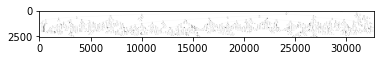

In [47]:
import pydotplus

data = tree.export_graphviz(dtree, out_file=None, feature_names=columns[:-1])
graph = pydotplus.graph_from_dot_data(data)
graph.write_png('mydecisiontree.png')

img=pltimg.imread('mydecisiontree.png')
imgplot = plt.imshow(img)
plt.show() 

In [48]:
print(dtree.predict([[0, 0, 1, 0, 1, 2]])) 

[4]


In [49]:
val_split = pickle.load(open("./dataset/three_card_poker/val.pkl", "rb"))

samples = []

for key in val_split:
    cards = []
    for idx, value in enumerate(val_split[key]['attribute_label']):
        if value == 1:
            cards.append(idx)
    
    # same order as df columns
    values = [
        suit_map[concept_index_to_string(cards[0])[-1]],
        value_map[concept_index_to_string(cards[0])[:-1]],
        suit_map[concept_index_to_string(cards[1])[-1]],
        value_map[concept_index_to_string(cards[1])[:-1]],
        suit_map[concept_index_to_string(cards[2])[-1]],
        value_map[concept_index_to_string(cards[2])[:-1]]
    ]

    samples.append((values, val_split[key]['class_label']))

In [50]:
results = []

for sample in samples:
    if dtree.predict([sample[0]])[0] == sample[1]:
        results.append(1)
    else:
        results.append(0)
    
print("accuracy:", round((sum(results) / len(results)) * 100, 2))

accuracy: 96.13
